# Algoritmo de Grover em Qiskit

**Trabalho de Computação Quântica – Sistemas de Informação**

Este notebook acompanha o relatório técnico e cobre:

1. Implementação do algoritmo de Grover (oráculo, difusor, número ótimo de iterações).
2. Validação no simulador (`qiskit-aer`) para vários tamanhos de espaço de busca.
3. Busca com mais de um item marcado.
4. Uma aplicação de Sistemas de Informação: localizar registros em uma tabela não ordenada.
5. Comparação com a busca clássica (número de consultas e tempo real).
6. Efeito de ruído (modelo de ruído sintético) e execução opcional em hardware IBM Quantum.

**Convenção de bits do Qiskit:** o qubit `q0` é o bit menos significativo. A string `'101'` no resultado
da medida corresponde ao inteiro 5 (`q2=1, q1=0, q0=1`).

---

### Em linguagem simples (leia antes de rodar)

**O problema.** Imagine uma lista com 1 milhão de nomes embaralhados e você precisa achar um nome específico.
Sem nenhuma ordem, a única saída é olhar um por um. Em média você olha 500 mil nomes; no pior caso, 1 milhão.

**A ideia do Grover.** O computador quântico mantém **todas as posições da lista ao mesmo tempo** em um
estado chamado *superposição*, e cada posição recebe uma "nota" (a *amplitude*). No começo todas as notas
são iguais. O algoritmo repete dois passos:

1. **Marcar:** a posição certa tem a nota invertida (de positiva para negativa). Isso é o trabalho do *oráculo*.
2. **Amplificar:** uma operação (o *difusor*) faz as notas negativas subirem e as demais descerem um pouco.

A cada repetição, a nota da posição certa cresce. Ao final, **medir** o sistema devolve a posição certa
com probabilidade alta. Para 1 milhão de itens bastam cerca de **785 repetições**, em vez de centenas de milhares de olhadas.

**Cuidado com dois mal-entendidos comuns:**
* O computador quântico **não** testa todas as respostas e entrega a certa de graça. Se medirmos logo no começo, o resultado é aleatório. Todo o trabalho do algoritmo é fazer a resposta certa ficar muito mais provável antes de medir.
* O ganho é **quadrático** (raiz quadrada do número de itens), não mágico. Tudo bem para listas sem ordem; para dados com índice, o computador comum já é muito rápido.

**Glossário rápido**

| Termo | Significado simples |
|---|---|
| Qubit | Unidade de informação quântica; pode estar em 0, em 1 ou numa combinação dos dois |
| Superposição | Combinação de vários valores ao mesmo tempo, cada um com uma "nota" |
| Amplitude | A "nota" de cada valor; seu quadrado dá a probabilidade de aquele valor sair na medida |
| Medida | Olhar o resultado: o sistema "escolhe" um valor, com probabilidade dada pelas notas |
| Porta quântica | Operação sobre qubits (como uma porta lógica AND/OR, mas quântica) |
| Circuito | Sequência de portas, desenhada como no gráfico da seção 2 |
| Oráculo | Pedaço do circuito que reconhece a resposta certa (marca invertendo a nota) |
| Difusor | Pedaço do circuito que aumenta a nota da posição marcada |
| Iteração | Uma repetição do par "oráculo + difusor" |
| Consulta | Uma chamada ao oráculo; é a unidade usada para comparar com a busca clássica |
| Simulador | Programa que imita o computador quântico em um computador comum |

In [1]:
import math
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

print("Qiskit", qiskit.__version__)

# As figuras do relatório são salvas em ../figuras (ou ./figuras se rodar da raiz)
FIG_DIR = Path("figuras")
FIG_DIR.mkdir(exist_ok=True)

random.seed(42)
np.random.seed(42)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

Qiskit 2.6.2


## 1. Implementação

O algoritmo tem três blocos:

* **Superposição inicial:** Hadamard em todos os $n$ qubits, gerando $|s\rangle = \frac{1}{\sqrt N}\sum_x |x\rangle$, com $N = 2^n$.
* **Oráculo $O$:** inverte a fase dos estados marcados, $O|x\rangle = (-1)^{f(x)}|x\rangle$.
* **Difusor $D$:** reflexão em torno de $|s\rangle$, $D = 2|s\rangle\langle s| - I$. Em conjunto, $G = D\,O$ gira o vetor de estado de um ângulo $2\theta$ por iteração, com $\sin\theta = \sqrt{M/N}$.

O número ótimo de iterações é $k = \mathrm{round}\!\left(\frac{\pi}{4\theta} - \frac12\right) \approx \frac{\pi}{4}\sqrt{N/M}$, e a probabilidade de sucesso após $k$ iterações é $\sin^2\big((2k+1)\theta\big)$.

In [2]:
def _cz_multi(qc: QuantumCircuit, n: int) -> None:
    # Z multi-controlado: aplica fase -1 apenas ao estado |11...1>.
    if n == 1:
        qc.z(0)
    else:
        qc.h(n - 1)
        qc.mcx(list(range(n - 1)), n - 1)
        qc.h(n - 1)


def oraculo(n: int, marcados) -> QuantumCircuit:
    # Inverte a fase de cada estado em `marcados` (lista de inteiros).
    qc = QuantumCircuit(n, name="Oráculo")
    for m in marcados:
        bits = format(m, f"0{n}b")                      # bits[0] é o qubit n-1
        zeros = [i for i in range(n) if bits[n - 1 - i] == "0"]
        if zeros:
            qc.x(zeros)                                  # leva |m> para |11...1>
        _cz_multi(qc, n)                                 # fase -1 em |11...1>
        if zeros:
            qc.x(zeros)                                  # desfaz
    return qc


def difusor(n: int) -> QuantumCircuit:
    # Reflexão em torno da superposição uniforme: H X (CZ multi) X H.
    qc = QuantumCircuit(n, name="Difusor")
    qc.h(range(n))
    qc.x(range(n))
    _cz_multi(qc, n)
    qc.x(range(n))
    qc.h(range(n))
    return qc


def iteracoes_otimas(n: int, M: int = 1) -> int:
    N = 2 ** n
    theta = math.asin(math.sqrt(M / N))
    return max(0, round(math.pi / (4 * theta) - 0.5))


def prob_teorica(n: int, M: int, k: int) -> float:
    theta = math.asin(math.sqrt(M / 2 ** n))
    return math.sin((2 * k + 1) * theta) ** 2


def grover(n: int, marcados, k: int | None = None, medir: bool = True) -> QuantumCircuit:
    # Circuito completo de Grover com k iterações (padrão: número ótimo).
    if k is None:
        k = iteracoes_otimas(n, len(marcados))
    qc = QuantumCircuit(n, n if medir else 0, name=f"Grover n={n}")
    qc.h(range(n))
    orc, dif = oraculo(n, marcados), difusor(n)
    for _ in range(k):
        qc.compose(orc, inplace=True)
        qc.compose(dif, inplace=True)
        qc.barrier()
    if medir:
        qc.measure(range(n), range(n))
    return qc


def prob_exata(n: int, marcados, k: int) -> float:
    # Probabilidade de medir um item marcado, via vetor de estado (sem amostragem).
    sv = Statevector.from_instruction(grover(n, marcados, k, medir=False))
    probs = sv.probabilities()
    return float(sum(probs[m] for m in marcados))

## 2. Exemplo mínimo: 3 qubits, um item marcado

Espaço de busca de $N = 8$ elementos; o item procurado é `5` (`'101'`).
O número ótimo de iterações é 2.

N = 8, iterações ótimas k = 2, P(sucesso) teórica = 0.9453


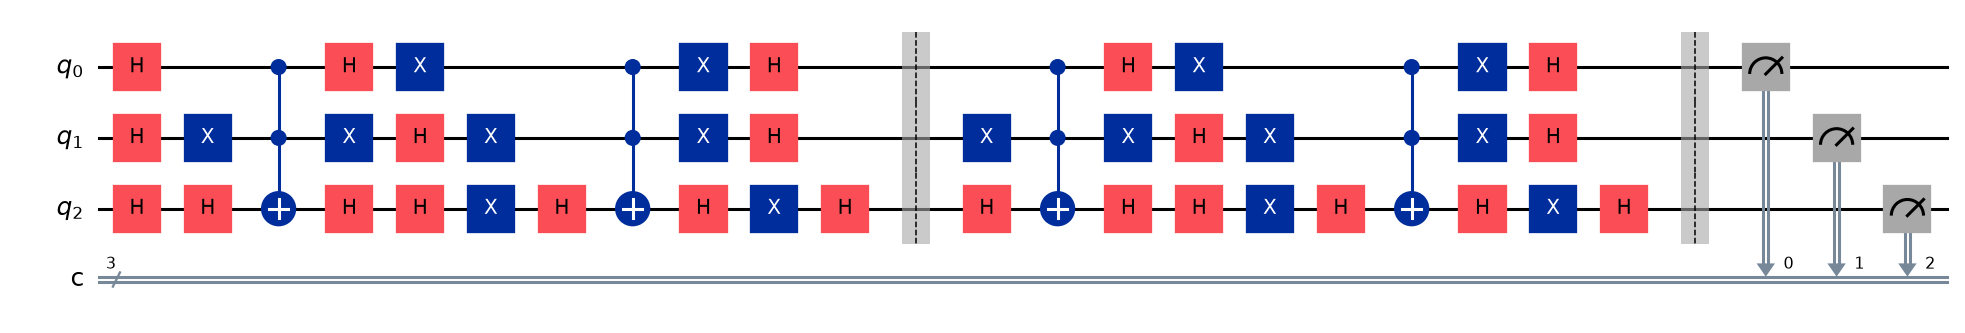

In [3]:
n, marcados = 3, [5]
k = iteracoes_otimas(n, len(marcados))
print(f"N = {2**n}, iterações ótimas k = {k}, P(sucesso) teórica = {prob_teorica(n, 1, k):.4f}")

qc = grover(n, marcados, k)
fig = qc.draw("mpl", fold=-1)
fig.savefig(FIG_DIR / "circuito_grover_n3.png", bbox_inches="tight", dpi=150)
fig

{'101': 3855, '110': 44, '011': 42, '010': 37, '000': 37, '111': 32, '001': 26, '100': 23}


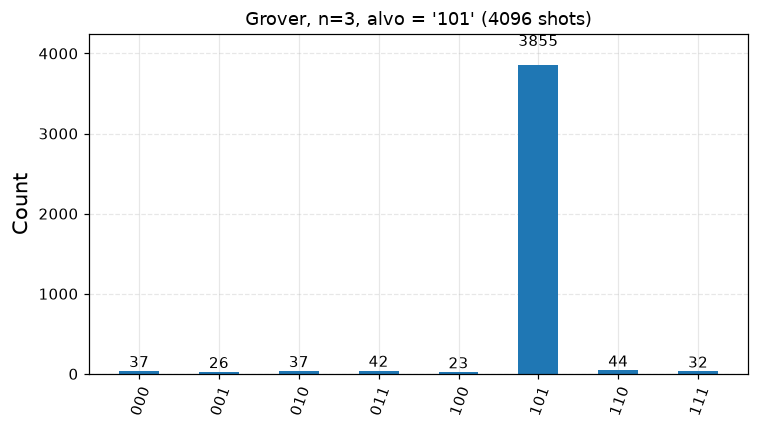

In [4]:
sim = AerSimulator()
SHOTS = 4096
res = sim.run(transpile(qc, sim), shots=SHOTS, seed_simulator=2026).result().get_counts()
print(dict(sorted(res.items(), key=lambda kv: -kv[1])))

fig = plot_histogram(res, title="Grover, n=3, alvo = '101' (4096 shots)", figsize=(7, 4))
fig.savefig(FIG_DIR / "histograma_n3.png", bbox_inches="tight", dpi=150)
fig

### 2.1 Vendo o que acontece por dentro (passo a passo)

O gráfico a seguir mostra a "nota" (amplitude) de cada uma das 8 posições em cada etapa, para o mesmo
exemplo (alvo `101` = posição 5). A linha tracejada é a **média** das notas.

* **Início:** todas as notas valem o mesmo (≈ 0,35).
* **Oráculo:** só a nota da posição 5 muda de sinal (fica negativa). A média das notas desce um pouco.
* **Difusor:** cada nota é "espelhada" em torno da média. Como a nota do alvo estava longe (abaixo) da média, ela
  vai para bem acima; as outras, que estavam um pouco acima da média, descem um pouco.
* Repetindo, a nota do alvo cresce e as demais encolhem. Depois de 2 repetições, o alvo concentra ≈ 94,5 % da probabilidade.

Nota técnica: o difusor implementado no circuito é $I - 2|s\rangle\langle s|$, que difere do difusor "de livro"
$2|s\rangle\langle s| - I$ só por um sinal global (sem efeito nas probabilidades). Para o gráfico mostrar a
reflexão em torno da média, multiplicamos por $-1$ após cada difusor.

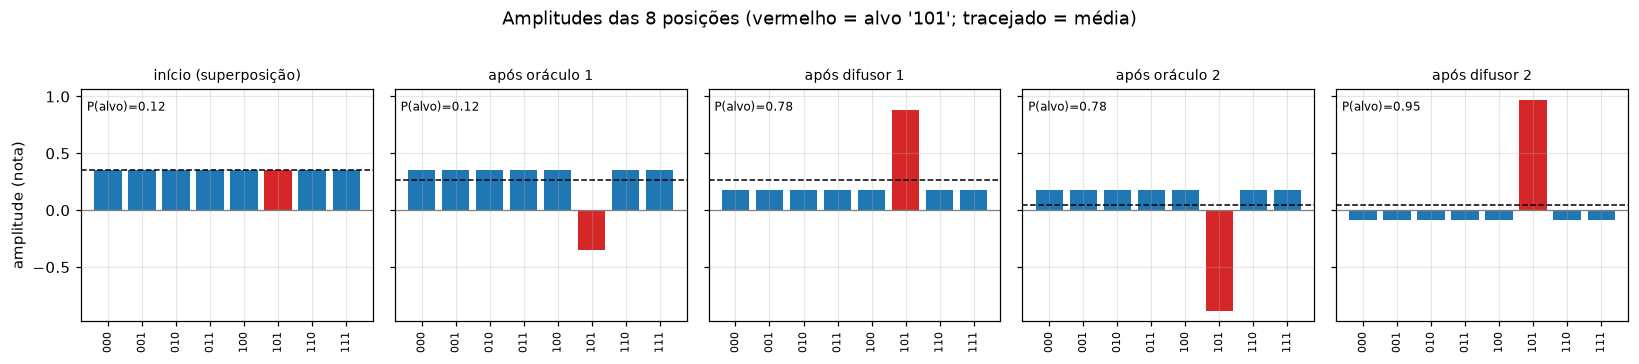

In [5]:
n, alvo = 3, 5
N = 2 ** n

def sv_de(qc):
    return Statevector.from_instruction(qc).data.real

etapas, rotulos = [], []
qc_p = QuantumCircuit(n); qc_p.h(range(n))
amp = sv_de(qc_p)
etapas.append(amp); rotulos.append("início (superposição)")

orc, dif = oraculo(n, [alvo]), difusor(n)
for it in (1, 2):
    qc_p = qc_p.compose(orc)
    amp = sv_de(qc_p)
    etapas.append(amp); rotulos.append(f"após oráculo {it}")
    qc_p = qc_p.compose(dif)
    amp = -sv_de(qc_p)          # -1: difusor de livro (ver nota acima)
    etapas.append(amp); rotulos.append(f"após difusor {it}")
    # o próximo estado de partida precisa ser coerente com o sinal aplicado
    qc_p.global_phase += math.pi

fig, axes = plt.subplots(1, len(etapas), figsize=(15, 3.2), sharey=True)
for ax, a, r in zip(axes, etapas, rotulos):
    cores = ["#d62728" if i == alvo else "#1f77b4" for i in range(N)]
    ax.bar(range(N), a, color=cores)
    ax.axhline(a.mean(), color="k", ls="--", lw=1)
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_title(r, fontsize=9)
    ax.set_xticks(range(N)); ax.set_xticklabels([format(i, "03b") for i in range(N)], rotation=90, fontsize=7)
    ax.text(0.02, 0.95, f"P(alvo)={a[alvo]**2:.2f}", transform=ax.transAxes, fontsize=8, va="top")
axes[0].set_ylabel("amplitude (nota)")
fig.suptitle("Amplitudes das 8 posições (vermelho = alvo '101'; tracejado = média)", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "amplitudes_passo_a_passo.png", bbox_inches="tight", dpi=150)
plt.show()

## 3. Probabilidade de sucesso em função do número de iterações

Grover **não** melhora sempre que se aumenta $k$: o vetor de estado continua girando e passa do alvo.
O gráfico compara a fórmula $\sin^2((2k+1)\theta)$ com o valor obtido do circuito.

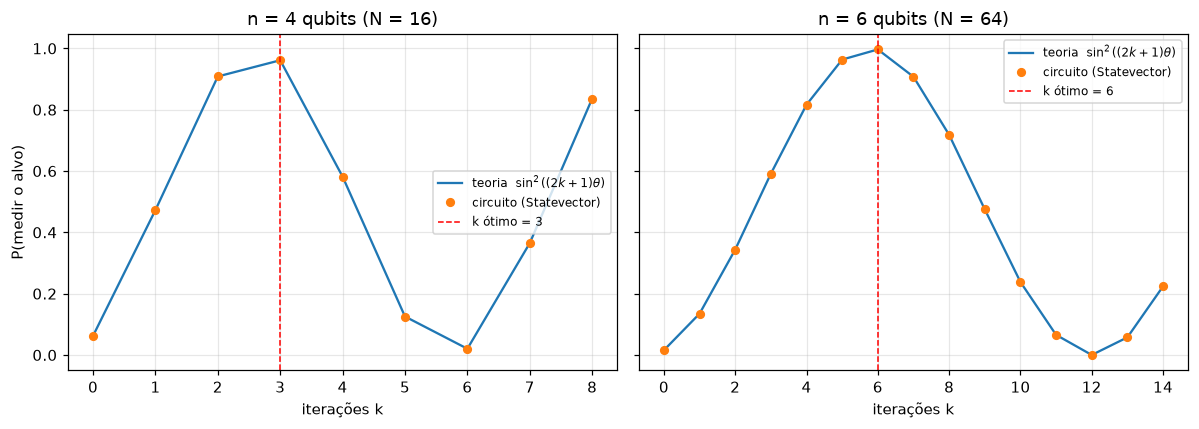

Maior diferença |teoria - circuito| (n=5): 1.03e-13


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, n in zip(axes, (4, 6)):
    marcados = [3]
    kmax = 2 * iteracoes_otimas(n, 1) + 2
    ks = np.arange(0, kmax + 1)
    teorica = [prob_teorica(n, 1, k) for k in ks]
    simulada = [prob_exata(n, marcados, int(k)) for k in ks]
    ax.plot(ks, teorica, "-", label="teoria  $\\sin^2((2k+1)\\theta)$")
    ax.plot(ks, simulada, "o", ms=5, label="circuito (Statevector)")
    kopt = iteracoes_otimas(n, 1)
    ax.axvline(kopt, color="red", ls="--", lw=1, label=f"k ótimo = {kopt}")
    ax.set_title(f"n = {n} qubits (N = {2**n})")
    ax.set_xlabel("iterações k")
    ax.legend(fontsize=8)
axes[0].set_ylabel("P(medir o alvo)")
fig.tight_layout()
fig.savefig(FIG_DIR / "prob_vs_iteracoes.png", bbox_inches="tight", dpi=150)
plt.show()

# Erro máximo entre circuito e teoria
err = max(abs(prob_teorica(5, 1, k) - prob_exata(5, [7], k)) for k in range(0, 12))
print(f"Maior diferença |teoria - circuito| (n=5): {err:.2e}")

## 4. Escalabilidade: iterações, probabilidade e custo do circuito

Tabela para $n = 2, \dots, 10$ com um item marcado. A profundidade e o número de portas
são medidos após `transpile` para a base `{u, cx}`; o `mcx` sem qubits auxiliares é decomposto
em muitas portas de 1 e 2 qubits, o que explica o crescimento do custo por iteração.

In [7]:
import pandas as pd

linhas = []
for n in range(2, 11):
    alvo = [2 ** n - 2]  # um alvo arbitrário
    k = iteracoes_otimas(n, 1)
    qc_n = grover(n, alvo, k)
    t = transpile(qc_n, basis_gates=["u", "cx"], optimization_level=1, seed_transpiler=1)
    ops = t.count_ops()
    linhas.append({
        "n": n, "N": 2 ** n, "k ótimo": k,
        "P teórica": prob_teorica(n, 1, k),
        "P circuito": prob_exata(n, alvo, k),
        "profundidade": t.depth(),
        "CX": ops.get("cx", 0),
        "portas 1q": ops.get("u", 0),
    })
df_escala = pd.DataFrame(linhas)
df_escala.style.format({"P teórica": "{:.4f}", "P circuito": "{:.4f}"}).hide(axis="index")

n,N,k ótimo,P teórica,P circuito,profundidade,CX,portas 1q
2,4,1,1.0000,1.0000,6,2,5
3,8,2,0.9453,0.9453,46,24,40
4,16,3,0.9613,0.9613,160,84,102
5,32,4,0.9992,0.9992,517,288,347
6,64,6,0.9966,0.9966,1219,984,1195
7,128,8,0.9956,0.9956,2073,1952,2305
8,256,12,0.9999,0.9999,3781,4080,4717
9,512,17,0.9994,0.9994,6308,7684,8739
10,1024,25,0.9995,0.9995,10676,14500,16276


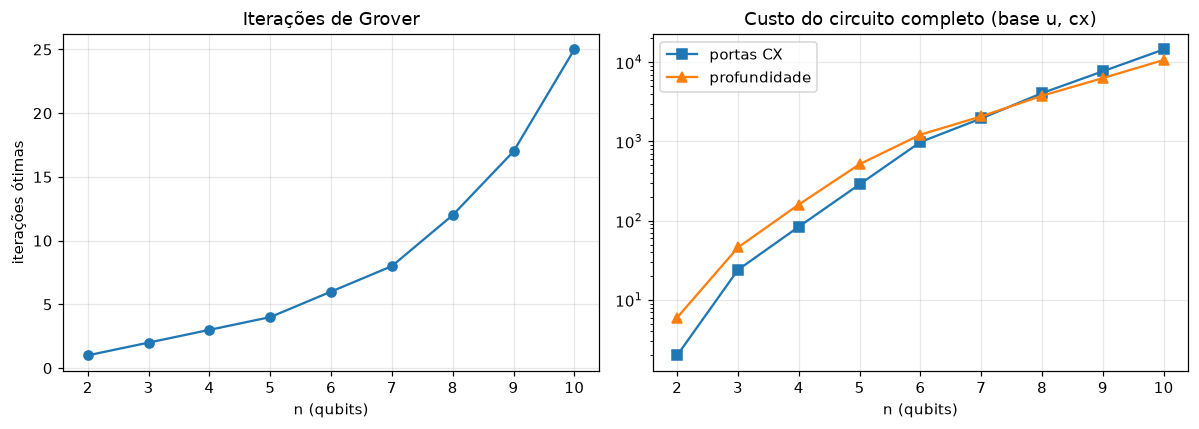

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(df_escala["n"], df_escala["k ótimo"], "o-")
ax[0].set_xlabel("n (qubits)"); ax[0].set_ylabel("iterações ótimas"); ax[0].set_title("Iterações de Grover")
ax[1].semilogy(df_escala["n"], df_escala["CX"], "s-", label="portas CX")
ax[1].semilogy(df_escala["n"], df_escala["profundidade"], "^-", label="profundidade")
ax[1].set_xlabel("n (qubits)"); ax[1].set_title("Custo do circuito completo (base u, cx)"); ax[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "escalabilidade_circuito.png", bbox_inches="tight", dpi=150)
plt.show()

## 5. Mais de um item marcado

Com $M$ itens marcados, $\theta = \arcsin\sqrt{M/N}$ e o número ótimo de iterações cai para $\approx \frac{\pi}{4}\sqrt{N/M}$.
Aqui: $n = 4$ ($N = 16$) com $M = 1, 2, 4$.

M=1: marcados=[11], k ótimo=3, P teórica=0.9613, P circuito=0.9613
M=2: marcados=[3, 12], k ótimo=2, P teórica=0.9453, P circuito=0.9453
M=4: marcados=[1, 6, 10, 15], k ótimo=1, P teórica=1.0000, P circuito=1.0000


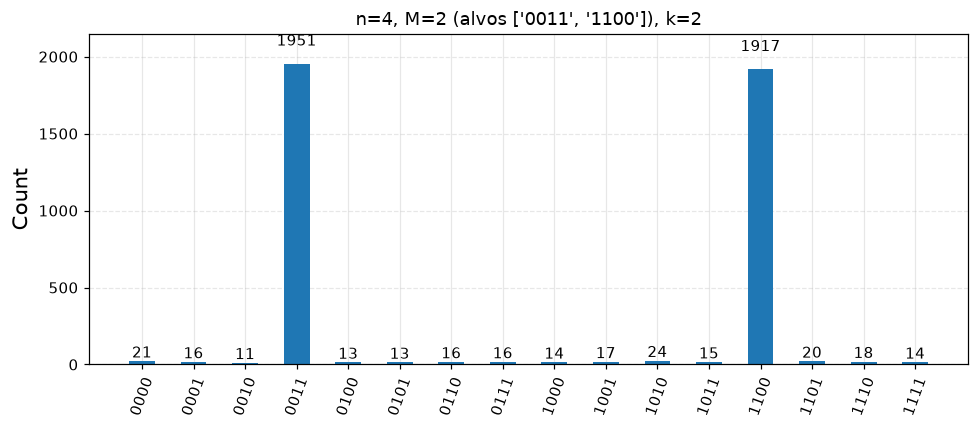

In [9]:
n = 4
casos = {1: [11], 2: [3, 12], 4: [1, 6, 10, 15]}
for M, marc in casos.items():
    k = iteracoes_otimas(n, M)
    p_c = prob_exata(n, marc, k)
    print(f"M={M}: marcados={marc}, k ótimo={k}, P teórica={prob_teorica(n, M, k):.4f}, P circuito={p_c:.4f}")

marc = casos[2]
qc2 = grover(n, marc)
cont = sim.run(transpile(qc2, sim), shots=SHOTS, seed_simulator=2026).result().get_counts()
rot = {format(m, f"0{n}b") for m in marc}
fig = plot_histogram(cont, title=f"n=4, M=2 (alvos {sorted(rot)}), k={iteracoes_otimas(n, 2)}", figsize=(9, 4))
fig.savefig(FIG_DIR / "histograma_m2.png", bbox_inches="tight", dpi=150)
fig

## 6. Aplicação em Sistemas de Informação: busca em tabela não ordenada

Considere uma tabela de **32 pedidos** (`n = 5` qubits indexam as linhas) sem índice. Queremos
as linhas com `status == "ATRASADO"` e `valor > 8000`.

**Ressalva importante:** neste notebook o oráculo é construído a partir da lista de índices que
satisfazem o predicado (calculada classicamente). Isso serve para **demonstrar o fluxo de Grover**; num
cenário real, o oráculo seria um circuito reversível que avalia o predicado sobre os dados
(por exemplo, via QRAM), e o custo de carregar os dados poderia anular a vantagem.

In [10]:
rng = np.random.default_rng(7)
status_opcoes = ["PAGO", "PENDENTE", "ATRASADO", "CANCELADO"]
pedidos = pd.DataFrame({
    "id_pedido": 1000 + np.arange(32),
    "status": rng.choice(status_opcoes, 32, p=[0.45, 0.25, 0.2, 0.1]),
    "valor": rng.integers(100, 12000, 32),
})

def predicado(linha) -> bool:
    return linha["status"] == "ATRASADO" and linha["valor"] > 8000

marcados_si = [i for i, lin in pedidos.iterrows() if predicado(lin)]
# Garante um caso interessante e determinístico caso nenhuma linha satisfaça
if not marcados_si:
    pedidos.loc[19, ["status", "valor"]] = ["ATRASADO", 9500]
    marcados_si = [19]
print("Linhas que satisfazem o predicado:", marcados_si)
pedidos.loc[marcados_si]

Linhas que satisfazem o predicado: [5, 8]


,id_pedido,status,valor
5,1005,ATRASADO,8335
8,1008,ATRASADO,8679


N=32, M=2, iterações=3, P teórica=0.9613
Resultado mais frequente: 00101 (linha 5), 48.3% dos disparos
Fração dos disparos que cai em linha válida: 95.9%


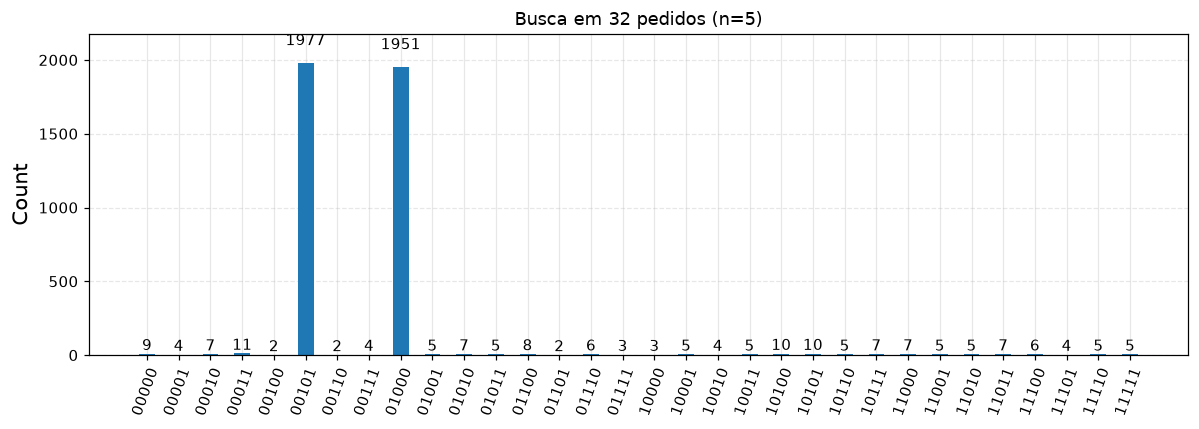

In [11]:
n = 5
M = len(marcados_si)
k = iteracoes_otimas(n, M)
qc_si = grover(n, marcados_si, k)
cont_si = sim.run(transpile(qc_si, sim), shots=SHOTS, seed_simulator=2026).result().get_counts()

mais_frequente = max(cont_si, key=cont_si.get)
print(f"N=32, M={M}, iterações={k}, P teórica={prob_teorica(n, M, k):.4f}")
print(f"Resultado mais frequente: {mais_frequente} (linha {int(mais_frequente, 2)}), "
      f"{cont_si[mais_frequente] / SHOTS:.1%} dos disparos")

acertos = sum(v for b, v in cont_si.items() if int(b, 2) in marcados_si) / SHOTS
print(f"Fração dos disparos que cai em linha válida: {acertos:.1%}")

fig = plot_histogram(cont_si, title="Busca em 32 pedidos (n=5)", figsize=(11, 4))
fig.savefig(FIG_DIR / "histograma_aplicacao_si.png", bbox_inches="tight", dpi=150)
fig

## 7. Comparação com a abordagem clássica

Para busca em lista não ordenada com um item marcado, o melhor algoritmo clássico (determinístico
ou aleatório) precisa de $\approx N/2$ consultas em média e $N$ no pior caso. Grover usa
$\approx \frac{\pi}{4}\sqrt{N}$ chamadas ao oráculo.

### 7.1 Número de consultas ao oráculo

* **Clássico:** simulação Monte Carlo de busca linear com ordem aleatória (média de 3000 execuções).
* **Grover:** número de iterações $k$ (cada iteração = 1 consulta), com a probabilidade de sucesso correspondente.

In [12]:
def consultas_classicas(N: int, alvo: int, rng) -> int:
    ordem = rng.permutation(N)
    return int(np.where(ordem == alvo)[0][0]) + 1  # nº de consultas até achar o alvo

rng = np.random.default_rng(1)
linhas = []
for n in range(2, 13):
    N = 2 ** n
    media_cl = np.mean([consultas_classicas(N, int(rng.integers(N)), rng) for _ in range(3000)])
    k = iteracoes_otimas(n, 1)
    linhas.append({"n": n, "N": N, "clássico (média)": media_cl, "clássico (pior)": N,
                   "Grover (k)": k, "P sucesso Grover": prob_teorica(n, 1, k)})
df_cmp = pd.DataFrame(linhas)
df_cmp.style.format({"clássico (média)": "{:.1f}", "P sucesso Grover": "{:.4f}"}).hide(axis="index")

n,N,clássico (média),clássico (pior),Grover (k),P sucesso Grover
2,4,2.5,4,1,1.0000
3,8,4.5,8,2,0.9453
4,16,8.6,16,3,0.9613
5,32,16.5,32,4,0.9992
6,64,32.8,64,6,0.9966
7,128,63.5,128,8,0.9956
8,256,129.7,256,12,0.9999
9,512,255.5,512,17,0.9994
10,1024,509.8,1024,25,0.9995
11,2048,1023.1,2048,35,1.0000


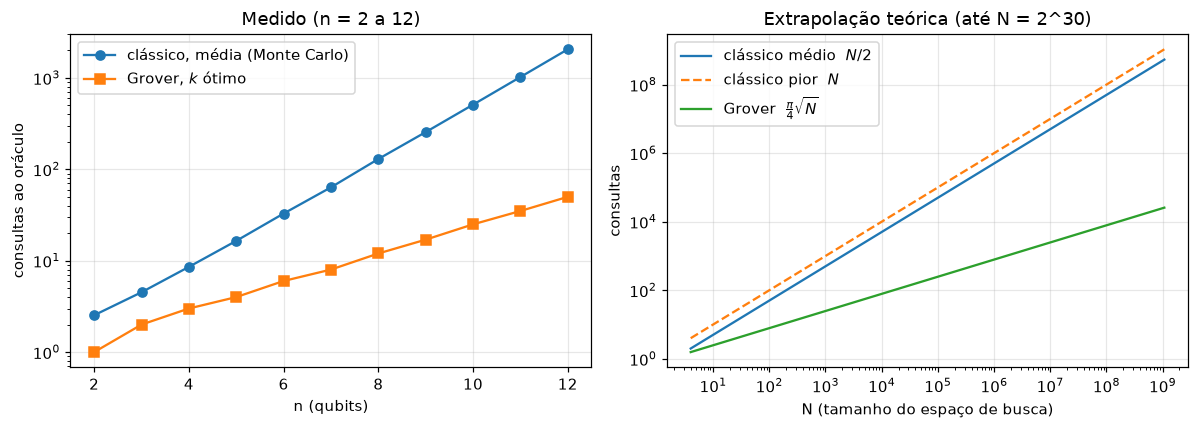

In [13]:
ns = np.arange(2, 31)
Ns = 2.0 ** ns
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(df_cmp["n"], df_cmp["clássico (média)"], "o-", label="clássico, média (Monte Carlo)")
ax[0].plot(df_cmp["n"], df_cmp["Grover (k)"], "s-", label="Grover, $k$ ótimo")
ax[0].set_yscale("log"); ax[0].set_xlabel("n (qubits)"); ax[0].set_ylabel("consultas ao oráculo")
ax[0].set_title("Medido (n = 2 a 12)"); ax[0].legend()

ax[1].loglog(Ns, Ns / 2, "-", label="clássico médio  $N/2$")
ax[1].loglog(Ns, Ns, "--", label="clássico pior  $N$")
ax[1].loglog(Ns, np.pi / 4 * np.sqrt(Ns), "-", label=r"Grover  $\frac{\pi}{4}\sqrt{N}$")
ax[1].set_xlabel("N (tamanho do espaço de busca)"); ax[1].set_ylabel("consultas")
ax[1].set_title("Extrapolação teórica (até N = 2^30)"); ax[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "comparacao_consultas.png", bbox_inches="tight", dpi=150)
plt.show()

### 7.2 Tempo de execução real (simulador × Python clássico)

A vantagem de Grover está em **consultas** ao oráculo, não em tempo de relógio **no simulador**:
simular $n$ qubits custa memória e tempo $\sim 2^n$ numa máquina clássica. O experimento abaixo mede isso
para evidenciar que o simulador só serve para validar a lógica, e não para obter ganho de desempenho.

n,N,tempo clássico (s),tempo simulador (s),acerto
3,8,8.90e-07,0.005,0.947
4,16,8.05e-07,0.006,0.961
5,32,1.14e-06,0.008,0.999
6,64,2.28e-06,0.010,0.996
7,128,1.21e-06,0.014,0.994
8,256,1.15e-05,0.021,1.000
9,512,6.34e-06,0.031,1.000
10,1024,3.00e-06,0.061,1.000
11,2048,3.78e-05,0.069,1.000
12,4096,2.08e-04,0.172,1.000


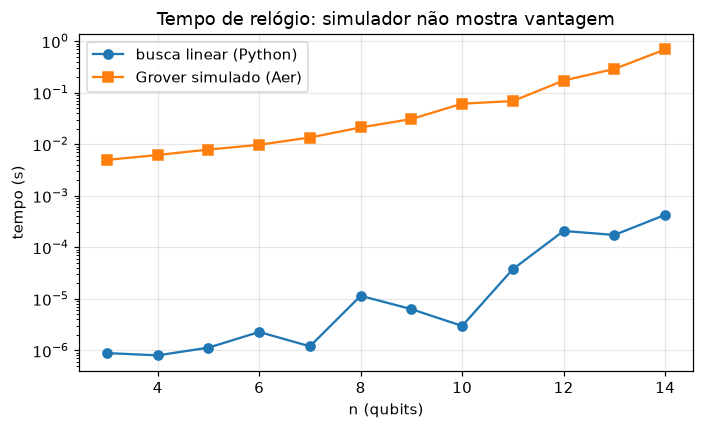

In [14]:
sim_sv = AerSimulator(method="statevector")
linhas = []
for n in range(3, 15):
    N = 2 ** n
    alvo = N - 3
    # Clássico: busca linear em uma lista
    lista = list(range(N))
    random.shuffle(lista)
    t0 = time.perf_counter()
    for _ in range(20):
        lista.index(alvo)
    t_cl = (time.perf_counter() - t0) / 20

    # Quântico simulado: transpile + execução (somente a execução é cronometrada)
    qc_n = transpile(grover(n, [alvo]), sim_sv, optimization_level=0)
    t0 = time.perf_counter()
    cts = sim_sv.run(qc_n, shots=1024, seed_simulator=2026).result().get_counts()
    t_q = time.perf_counter() - t0
    linhas.append({"n": n, "N": N, "tempo clássico (s)": t_cl, "tempo simulador (s)": t_q,
                   "acerto": cts.get(format(alvo, f"0{n}b"), 0) / 1024})
df_tempo = pd.DataFrame(linhas)
display(df_tempo.style.format({"tempo clássico (s)": "{:.2e}", "tempo simulador (s)": "{:.3f}", "acerto": "{:.3f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.semilogy(df_tempo["n"], df_tempo["tempo clássico (s)"], "o-", label="busca linear (Python)")
ax.semilogy(df_tempo["n"], df_tempo["tempo simulador (s)"], "s-", label="Grover simulado (Aer)")
ax.set_xlabel("n (qubits)"); ax.set_ylabel("tempo (s)"); ax.legend()
ax.set_title("Tempo de relógio: simulador não mostra vantagem")
fig.tight_layout()
fig.savefig(FIG_DIR / "tempo_execucao.png", bbox_inches="tight", dpi=150)
plt.show()

## 8. Efeito do ruído

Hardware atual tem erros de porta. Como as iterações de Grover são profundas (muitas portas `cx`),
a probabilidade de sucesso cai conforme $n$ cresce. Usamos um **modelo de ruído sintético** (erro
depolarizante de 0,1% em portas de 1 qubit e 1% em `cx`), valores típicos da ordem de grandeza de
dispositivos superconductores atuais. Não é o ruído de um dispositivo específico.

config,ideal,"ruído baixo (p1=0,05%, p2=0,5%)","ruído típico (p1=0,1%, p2=1%)"
n,,,
2,1.000,0.989,0.980
3,0.946,0.851,0.766
4,0.962,0.668,0.474
5,1.000,0.300,0.107
6,0.997,0.031,0.015


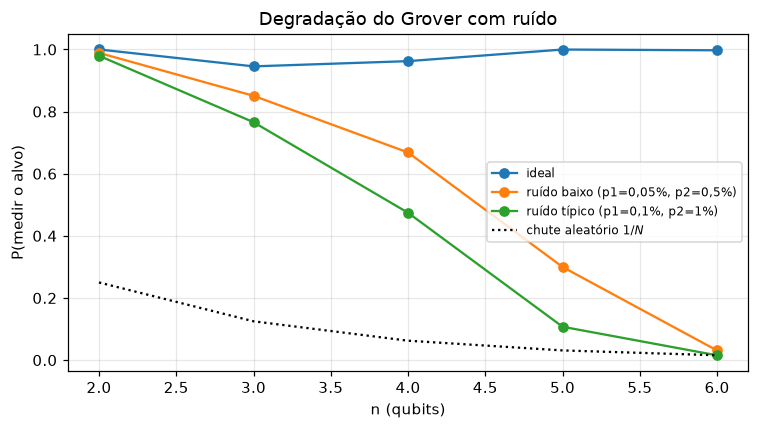

In [15]:
from qiskit_aer.noise import NoiseModel, depolarizing_error

def modelo_ruido(p1: float, p2: float) -> NoiseModel:
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["u"])
    nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cx"])
    return nm

configs = {"ideal": None,
           "ruído baixo (p1=0,05%, p2=0,5%)": modelo_ruido(0.0005, 0.005),
           "ruído típico (p1=0,1%, p2=1%)": modelo_ruido(0.001, 0.01)}

SHOTS_R = 4096
linhas = []
for n in range(2, 7):
    alvo = [2 ** n - 2]
    k = iteracoes_otimas(n, 1)
    base = transpile(grover(n, alvo, k), basis_gates=["u", "cx"], optimization_level=1, seed_transpiler=1)
    for nome, nm in configs.items():
        s = AerSimulator(noise_model=nm) if nm else AerSimulator()
        cts = s.run(base, shots=SHOTS_R, seed_simulator=11).result().get_counts()
        linhas.append({"n": n, "config": nome,
                       "P(sucesso)": cts.get(format(alvo[0], f"0{n}b"), 0) / SHOTS_R,
                       "acerto aleatório": 1 / 2 ** n})
df_ruido = pd.DataFrame(linhas)
display(df_ruido.pivot(index="n", columns="config", values="P(sucesso)").round(3))

fig, ax = plt.subplots(figsize=(7, 4))
for nome in configs:
    d = df_ruido[df_ruido["config"] == nome]
    ax.plot(d["n"], d["P(sucesso)"], "o-", label=nome)
d0 = df_ruido[df_ruido["config"] == "ideal"]
ax.plot(d0["n"], d0["acerto aleatório"], "k:", label="chute aleatório $1/N$")
ax.set_xlabel("n (qubits)"); ax.set_ylabel("P(medir o alvo)"); ax.legend(fontsize=8)
ax.set_title("Degradação do Grover com ruído")
fig.tight_layout()
fig.savefig(FIG_DIR / "efeito_ruido.png", bbox_inches="tight", dpi=150)
plt.show()

## 9. Execução em hardware real (IBM Quantum) – opcional

Esta seção só roda se a variável de ambiente `IBM_QUANTUM_TOKEN` estiver definida (chave de API da
conta em <https://quantum.cloud.ibm.com>). Opcionalmente defina `IBM_QUANTUM_INSTANCE` (CRN da instância).
**Nunca escreva o token dentro do notebook ou do repositório.**

Uso sugerido: $n = 2$ ou $3$ (poucos qubits e poucas portas `cx`), que é o que o hardware atual
consegue executar com resultado ainda visível acima do ruído.

No PowerShell, antes de abrir o Jupyter:

```powershell
$env:IBM_QUANTUM_TOKEN = "SUA_CHAVE"
```

In [16]:
RESULTADO_HW = None
token = os.environ.get("IBM_QUANTUM_TOKEN")

if not token:
    print("IBM_QUANTUM_TOKEN não definido: seção de hardware ignorada.")
else:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=token,
                                   instance=os.environ.get("IBM_QUANTUM_INSTANCE"))
    backend = service.least_busy(operational=True, simulator=False, min_num_qubits=5)
    print("Backend escolhido:", backend.name)

    n_hw, alvo_hw = 3, [5]
    qc_hw = grover(n_hw, alvo_hw)
    pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
    isa = pm.run(qc_hw)
    print("Profundidade:", isa.depth(), "| CX/ECR de 2 qubits:", isa.num_nonlocal_gates())

    job = SamplerV2(mode=backend).run([isa], shots=4096)
    print("Job:", job.job_id())
    RESULTADO_HW = job.result()[0].data.c.get_counts()   # registro clássico padrão: 'c'
    print(dict(sorted(RESULTADO_HW.items(), key=lambda kv: -kv[1])))

IBM_QUANTUM_TOKEN não definido: seção de hardware ignorada.


In [17]:
if RESULTADO_HW:
    ideal = sim.run(transpile(grover(3, [5]), sim), shots=4096, seed_simulator=2026).result().get_counts()
    fig = plot_histogram([ideal, RESULTADO_HW], legend=["simulador ideal", f"hardware ({backend.name})"],
                         title="Grover n=3, alvo '101'", figsize=(9, 4))
    fig.savefig(FIG_DIR / "histograma_hardware.png", bbox_inches="tight", dpi=150)
    display(fig)
else:
    print("Sem resultado de hardware para plotar.")

Sem resultado de hardware para plotar.


## 10. Conclusões

* O circuito implementado reproduz a fórmula teórica $\sin^2((2k+1)\theta)$ com diferença numérica desprezível (seção 3).
* O número de consultas cresce como $\sqrt N$, contra $N/2$ da busca linear clássica (seção 7.1): ganho quadrático.
* No simulador não há ganho de tempo, já que simular $n$ qubits custa $\sim 2^n$ (seção 7.2).
* O custo por iteração (profundidade e portas `cx`) cresce com $n$ e o ruído destrói o ganho rapidamente (seções 4 e 8).
* Em aplicações de dados, o gargalo prático é construir o oráculo e carregar os dados em forma quântica (seção 6).